# 1 km and 500 m flow direction grids for the UK

Derives 1 km and 500 m D8 flow direction rasters for the British Isles in British National Grid (EPSG:27700)
from the HydroSHEDS v1 hydrologically conditioned 3" DEM (`eu_con_3s`), using the same method as the 2 km grid
in `2026-11-02_1_uk-flowdir-2km.ipynb`. Both grids are fully resolved: every land cell has a strictly downhill
path to the sea, so there are no pits, flats, depressions or loops.

The method, run once for each resolution:

1. **Grid.** Aligned to the BNG origin, with the same extent as the 2 km grid (GB, the island of Ireland and
   the Isle of Man). Every 2 km cell is exactly 2×2 1 km cells and 4×4 500 m cells.
2. **Aggregation.** Each cell takes the *minimum* elevation of the 90 m land pixels inside it, which keeps
   the river channels burned into the HydroSHEDS DEM. A cell is land if at least half of it is land. North
   of 60°N (northern Shetland), where HydroSHEDS stops, EuroDEM 2023 is used.
3. **Land/sea mask.** Mainland Europe (anything touching the grid edge) is removed, and enclosed inland
   water is treated as land so it is routed through.
4. **River enforcement (GB only).** OS Open Rivers rivers with at least `MIN_UP_KM` of channel upstream are
   rasterised, given D8 directions that follow the mapped river, and lowered by 50 m. The threshold is
   lower on finer grids, which can resolve smaller rivers (see below). Ireland is DEM-only. Two steps are
   new compared with the 2 km grid, because finer grids are more sensitive to errors in the river network:
   * links digitised the wrong way (mostly where rivers pass under canals) are reversed;
   * enforcement is released where it would hold water more than 50 m above the valley beside it.
5. **Conditioning.** Priority-Flood+ε ([Barnes et al., 2014](https://doi.org/10.1016/j.cageo.2013.04.024)),
   seeded from the coast and adapted so that enforced directions are downhill.
6. **Flow direction.** D8 steepest descent, in the ESRI encoding used by the HMF 5 km grid (`1` E, `2` SE,
   `4` S, `8` SW, `16` W, `32` NW, `64` N, `128` NE). Coastal cells drain straight to the sea.
7. **Validation.** Every land cell is traced to the sea, flow accumulation is checked against pysheds, and
   upstream areas at NRFA gauges are compared with their published catchment areas.

In [1]:
import os
import tomllib
import urllib.request
from pathlib import Path
from types import SimpleNamespace
import heapq
import numpy as np
import numba
import rasterio
from rasterio.transform import from_origin
from rasterio.warp import reproject, transform_bounds, Resampling
from rasterio.windows import from_bounds, Window
from pyproj import Transformer
from scipy import ndimage
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra, breadth_first_order
import shapely
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Data locations are set in paths.toml in the project root (copy paths.example.toml to make it), or in the
# file named by the PFASE_PATHS environment variable. Relative paths in it are relative to that file
path_config = Path(os.environ.get('PFASE_PATHS', '../paths.toml')).expanduser().resolve()
if not path_config.exists():
    raise FileNotFoundError(f'{path_config} not found. Copy paths.example.toml to paths.toml and set the paths in it')
config = tomllib.loads(path_config.read_text())


def config_path(key):
    return (path_config.parent / Path(config[key]).expanduser()).resolve()

path_hydrosheds = config_path('hydrosheds_dem')
path_eurodem = config_path('eurodem')
path_rivers = config_path('os_rivers')
path_nrfa = config_path('nrfa_stations')
path_out = config_path('data_dir')
missing = [p for p in (path_hydrosheds, path_eurodem, path_rivers) if not p.exists()]
if missing:
    raise FileNotFoundError(f'Inputs not found (paths.example.toml lists their sources): {", ".join(map(str, missing))}')
path_out.mkdir(parents=True, exist_ok=True)
if not path_nrfa.exists():  # NRFA gauging station list, downloaded on first run
    path_nrfa.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve('https://nrfaapps.ceh.ac.uk/nrfa/ws/station-info?station=*&format=csv'
                               '&fields=id,name,catchment-area,easting,northing,grid-reference', path_nrfa)

BNG = 'EPSG:27700'
RESOLUTIONS = [1000, 500]
NODATA = -9999
MIN_UP_KM = {1000: 1, 500: 1}  # Enforce rivers with at least this much channel length upstream (km)
BURN = 50  # and lower their cells by this much (m)
LIFT_TOL = 50  # Release enforcement where it holds water this far above the DEM, next to ground this much lower (m)
# Grid extent (BNG metres), as for the 2 km grid. x < 0 is needed to cover the west of Ireland
X0, X1, Y0, Y1 = -250_000, 700_000, 0, 1_250_000


def make_grid(res):
    ncol, nrow = (X1 - X0) // res, (Y1 - Y0) // res
    return SimpleNamespace(res=res, tag=f'{res:05d}', ncol=ncol, nrow=nrow, transform=from_origin(X0, Y1, res, res))


grids = {res: make_grid(res) for res in RESOLUTIONS}
for g in grids.values():
    print(f'{g.res} m grid: {g.ncol} cols x {g.nrow} rows')

1000 m grid: 950 cols x 1250 rows
500 m grid: 1900 cols x 2500 rows


## Aggregate the DEMs

`aggregate` reads the source DEM pixels under the grid and returns, for each cell, the minimum elevation of
its land pixels and the fraction of the cell that is land (sea is nodata in both DEMs). Cells outside the
source's coverage are NaN. At 500 m a cell still holds roughly 5×9 HydroSHEDS pixels (they are 3" square,
so about 50–60 m east–west in Britain), so the cell minimum still picks out the channel.

In [2]:
def aggregate(path, bounds, g):
    with rasterio.open(path) as src:
        win = from_bounds(*transform_bounds(BNG, src.crs, *bounds, densify_pts=101), transform=src.transform)
        win = win.intersection(Window(0, 0, src.width, src.height))
        c0, r0 = int(np.floor(win.col_off)), int(np.floor(win.row_off))
        win = Window(c0, r0, int(np.ceil(win.col_off + win.width)) - c0, int(np.ceil(win.row_off + win.height)) - r0)
        dem = src.read(1, window=win)
        src_transform, src_crs, src_nodata = src.window_transform(win), src.crs, src.nodata
    elev = np.full((g.nrow, g.ncol), np.nan, dtype=np.float32)
    frac = np.full((g.nrow, g.ncol), np.nan, dtype=np.float32)
    kw = dict(src_transform=src_transform, src_crs=src_crs, dst_transform=g.transform, dst_crs=BNG, dst_nodata=np.nan)
    reproject(dem.astype(np.float32), elev, src_nodata=src_nodata, resampling=Resampling.min, **kw)
    # The land mask has no nodata of its own (-1 never occurs), so sea pixels count towards the average
    reproject((dem != src_nodata).astype(np.float32), frac, src_nodata=-1, resampling=Resampling.average, **kw)
    return elev, frac


def merge_sources(g):
    # HydroSHEDS wherever a cell lies entirely south of 60°N, EuroDEM everywhere else
    elev_hs, frac_hs = aggregate(path_hydrosheds, (X0, Y0, X1, Y1), g)
    elev_eu, frac_eu = aggregate(path_eurodem, (X0, 1_000_000, X1, Y1), g)
    xe, ye = np.meshgrid(X0 + g.res * np.arange(g.ncol + 1), Y1 - g.res * np.arange(g.nrow + 1))
    _, lat = Transformer.from_crs(BNG, 'EPSG:4326', always_xy=True).transform(xe, ye)
    corners = [lat[:-1, :-1], lat[:-1, 1:], lat[1:, :-1], lat[1:, 1:]]
    g.use_eu = np.maximum.reduce(corners) > 60
    g.elev = np.where(g.use_eu, elev_eu, elev_hs)
    g.frac = np.where(g.use_eu, frac_eu, frac_hs)
    # Check the join: compare the two sources over land cells in the 59-60°N band, where both exist
    band = (np.minimum.reduce(corners) > 59) & ~g.use_eu & (frac_hs >= 0.5) & (frac_eu >= 0.5)
    diff = elev_eu[band] - elev_hs[band]
    print(f'{g.res} m: 59-60°N overlap ({band.sum()} cells): EuroDEM - HydroSHEDS mean {diff.mean():.1f} m, '
          f'RMSE {np.sqrt((diff**2).mean()):.1f} m; {(g.use_eu & (g.frac >= 0.5)).sum()} land cells from EuroDEM')

In [3]:
for g in grids.values():
    merge_sources(g)

1000 m: 59-60°N overlap (644 cells): EuroDEM - HydroSHEDS mean 3.1 m, RMSE 7.3 m; 1447 land cells from EuroDEM


500 m: 59-60°N overlap (2633 cells): EuroDEM - HydroSHEDS mean 3.7 m, RMSE 7.6 m; 5791 land cells from EuroDEM


## Land/sea mask

As for the 2 km grid: land is any cell that is at least 50% land, land masses touching the grid edge (mainland
Europe) are removed, and non-land cells that aren't connected to the open sea are turned into land, taking
the elevation of the nearest land cell if they have none of their own.

In [4]:
EIGHT = np.ones((3, 3), dtype=bool)


def land_mask(g):
    land = np.nan_to_num(g.frac) >= 0.5
    labels, _ = ndimage.label(land, structure=EIGHT)
    edge_labels = np.unique(np.concatenate([labels[0], labels[-1], labels[:, 0], labels[:, -1]]))
    edge_labels = edge_labels[edge_labels > 0]
    n_removed = np.isin(labels, edge_labels).sum()
    land &= ~np.isin(labels, edge_labels)

    water_labels, _ = ndimage.label(~land, structure=EIGHT)
    sea_labels = np.unique(np.concatenate([water_labels[0], water_labels[-1], water_labels[:, 0], water_labels[:, -1]]))
    enclosed = ~land & ~np.isin(water_labels, sea_labels)
    land |= enclosed
    nearest = ndimage.distance_transform_edt(np.isnan(g.elev) | ~land, return_distances=False, return_indices=True)
    g.elev = np.where(land & np.isnan(g.elev), g.elev[tuple(nearest)], g.elev)

    assert not land[[0, -1]].any() and not land[:, [0, -1]].any(), 'Land on the grid edge'
    assert not np.isnan(g.elev[land]).any()
    g.land, g.n_land = land, land.sum()
    print(f'{g.res} m: removed {n_removed} cells of land touching the grid edge; {enclosed.sum()} enclosed non-land cells '
          f'converted to land; {g.n_land} land cells ({g.n_land * g.res**2 / 1e6:,.0f} km2) in '
          f'{ndimage.label(land, structure=EIGHT)[1]} land masses')

In [5]:
for g in grids.values():
    land_mask(g)

1000 m: removed 6729 cells of land touching the grid edge; 431 enclosed non-land cells converted to land; 317819 land cells (317,819 km2) in 165 land masses


500 m: removed 26912 cells of land touching the grid edge; 337 enclosed non-land cells converted to land; 1270147 land cells (317,537 km2) in 397 land masses


## Enforce the OS Open Rivers network

As for the 2 km grid, canals are dropped and each `WatercourseLink`'s upstream channel length is found with a
topological sort of the node graph (links in loops get −1 and are left out).

**Repairing link directions.** At finer resolutions, errors in the network's directions start to matter.
Where a river passes under a canal, OS Open Rivers often has the river's link digitised the wrong way, so
the mapped river runs into a dead end. Examples are the Dee under the Pontcysyllte Aqueduct, the Wyre under
the Lancaster Canal at Garstang, and the Trent at Great Haywood. Enforced cells along a reversed link can
only be reached from upstream, so they wall in everything above them. On a first 500 m run, the whole upper
Dee (about 250 km²) had to be filled and drained over a 271 m ridge to get out. `repair_directions`:

1. finds the nodes that have no directed path to a proper end: a sink within 1 km of the sea, or a node
   on a canal;
2. for each of those, takes the shortest path through the network, ignoring direction and measured by
   channel length, to a node that does drain;
3. reverses any link on that path that points the wrong way.

Nodes that already drain are left alone, so the rest of the network is unchanged. Isolated streams that
don't connect to anything stay as they are.

`rasterise_rivers` turns each link into its ordered sequence of grid cells, from the link's vertices after
densifying it to at most 1/20 of a cell between vertices (so consecutive points are always in the same or
neighbouring cells). Where the line wanders out of a cell and back, the loop is cut out. Each cell then points
at the next cell along the link. Links are processed from the largest upstream length down, so where rivers
share a cell the bigger one sets its direction. Loops left in the enforced directions are broken by dropping
the enforcement on the cell belonging to the smallest river.

**Threshold.** On the 2 km grid, 10 km of upstream channel (roughly 15 km² of catchment) was the best
setting. Finer grids can resolve smaller rivers, so lower thresholds were compared against the NRFA gauges
(median absolute error in upstream area, gauges ≥ 10 km², with the number of river cells the flood had to
release from enforcement):

| Rivers enforced (km upstream) | 1 km: median error, gauges ≥ 50 km² | 1 km: 10–50 km² | 1 km: within 10% (≥ 50 km²) | 1 km: cells released by lift check | 500 m: median error, gauges ≥ 50 km² | 500 m: 10–50 km² | 500 m: within 10% (≥ 50 km²) | 500 m: cells released by lift check |
|---|---|---|---|---|---|---|---|---|
| none (DEM only) | 6.4% | 13.7% | 63% | – | 2.2% | 5.4% | 82% | – |
| 0.5 | | | | | 0.94% | 2.4% | 95% | 226 |
| **1** | **1.9%** | **6.2%** | **87%** | **41** | **0.92%** | **2.4%** | **95%** | **229** |
| 1.5 | 2.1% | 6.3% | 87% | 31 | | | | |
| 2.5 | 2.2% | 7.9% | 86% | 24 | 1.0% | 2.6% | 95% | 172 |
| 5 | 2.8% | 8.0% | 83% | 7 | 1.1% | 2.8% | 93% | 34 |
| 10 | 3.0% | 9.6% | 79% | 5 | 1.2% | 3.8% | 92% | 26 |

For comparison, the 2 km grid with its 10 km threshold has a median error of 4.5% at the gauges ≥ 50 km². With
the direction repair, no setting needs any cells released because the flood stalled.

Both grids use **1 km**. It is the best or joint-best setting at both resolutions; at 500 m, 0.5 km gives the same errors, so there is no reason to enforce more.

In [6]:
def drained_nodes(s, e, n, seeds):
    # Nodes with a directed path to a seed node: search upstream from the seeds along reversed links
    m = coo_matrix((np.ones(len(s) + len(seeds)), (np.r_[e, np.full(len(seeds), n)], np.r_[s, seeds])), shape=(n + 1, n + 1))
    out = np.zeros(n + 1, dtype=bool)
    out[breadth_first_order(m.tocsr(), n, directed=True, return_predecessors=False)] = True
    return out[:n]


def repair_directions(links, canal_nodes, land, res):
    # links: non-canal links. land: a land mask on a res grid, to find sinks near the sea
    links = links.copy()
    nodes = pd.Index(pd.concat([links.startNode, links.endNode]).unique())
    n = len(nodes)
    s, e = nodes.get_indexer(links.startNode), nodes.get_indexer(links.endNode)
    xy = np.zeros((n, 2))
    xy[s] = shapely.get_coordinates(shapely.get_point(links.geometry.values, 0))
    xy[e] = shapely.get_coordinates(shapely.get_point(links.geometry.values, -1))
    dist_to_sea = ndimage.distance_transform_edt(land)[((Y1 - xy[:, 1]) // res).astype(int), ((xy[:, 0] - X0) // res).astype(int)] * res
    sink = np.bincount(s, minlength=n) == 0
    seeds = np.flatnonzero(sink & ((dist_to_sea <= 1000) | nodes.isin(canal_nodes)))
    drained = drained_nodes(s, e, n, seeds)

    length = links['length'].to_numpy(float) + 1.0
    undirected = coo_matrix((np.r_[length, length], (np.r_[s, e], np.r_[e, s])), shape=(n, n)).tocsr()
    _, pred, _ = dijkstra(undirected, indices=np.flatnonzero(drained), min_only=True, return_predecessors=True)
    link_of = pd.Series(np.arange(len(s)), index=pd.MultiIndex.from_arrays([s, e]))
    link_of = link_of[~link_of.index.duplicated()]
    flip = np.array([link_of[(pred[u], u)] for u in np.flatnonzero(~drained & (pred >= 0))
                     if (pred[u], u) in link_of.index and (u, pred[u]) not in link_of.index], dtype=int)
    links.loc[flip, ['startNode', 'endNode']] = links.loc[flip, ['endNode', 'startNode']].to_numpy()
    links.loc[flip, 'geometry'] = shapely.reverse(links.geometry.values[flip])
    s[flip], e[flip] = e[flip], s[flip].copy()
    n_still = (~drained_nodes(s, e, n, seeds)).sum()
    print(f'{n} nodes, {(~drained).sum()} without a path to the sea or a canal; reversed {len(flip)} links '
          f'({links.length.iloc[flip].sum() / 1e3:,.0f} km); {n_still} nodes (isolated streams) still without one')
    return links


@numba.njit
def upstream_length(start, end, length, n_nodes):
    # Upstream channel length (including itself) of each link, or -1 if it is in a loop
    order = np.argsort(start)
    first = np.searchsorted(start[order], np.arange(n_nodes + 1))
    remaining = np.zeros(n_nodes, dtype=np.int64)
    for e in end:
        remaining[e] += 1
    arriving = np.zeros(n_nodes)
    up = np.full(len(start), -1.0)
    queue = [n for n in range(n_nodes) if remaining[n] == 0]
    while len(queue) > 0:
        n = queue.pop()
        for idx in range(first[n], first[n + 1]):
            i = order[idx]
            up[i] = arriving[n] + length[i]
            arriving[end[i]] += up[i]
            remaining[end[i]] -= 1
            if remaining[end[i]] == 0:
                queue.append(end[i])
    return up

In [7]:
all_links = gpd.read_file(path_rivers, columns=['startNode', 'endNode', 'form', 'flow', 'length'])
assert (all_links.flow == 'in direction').all()
canals = all_links[all_links.form == 'canal']
g = grids[min(RESOLUTIONS)]
links = repair_directions(all_links[all_links.form != 'canal'].reset_index(drop=True),
                          pd.concat([canals.startNode, canals.endNode]), g.land, g.res)
nodes = pd.Index(pd.concat([links.startNode, links.endNode]).unique())
links['up_km'] = upstream_length(nodes.get_indexer(links.startNode), nodes.get_indexer(links.endNode),
                                 links['length'].to_numpy(float), len(nodes)) / 1e3
links = links.sort_values('up_km', ascending=False, ignore_index=True)
print(f'{len(links)} non-canal links, {(links.up_km < 0).sum()} of them in loops')

203764 nodes, 32154 without a path to the sea or a canal; reversed 339 links (601 km); 22984 nodes (isolated streams) still without one


199340 non-canal links, 301 of them in loops


In [8]:
@numba.njit
def rasterise_rivers(xy, first, up_km, land, x0, y1, res):
    # xy: vertices of all links, largest river first; first[l]: index of link l's first vertex (plus the end)
    nrow, ncol = land.shape
    target = np.full((nrow, ncol), -1, dtype=np.int64)
    target_up_km = np.zeros((nrow, ncol))
    seq = np.empty(xy.shape[0], dtype=np.int64)
    for l in range(len(first) - 1):
        n = 0
        for v in range(first[l], first[l + 1]):
            cell = int((y1 - xy[v, 1]) // res) * ncol + int((xy[v, 0] - x0) // res)
            m = n - 1
            while m >= 0 and seq[m] != cell:
                m -= 1
            if m >= 0:
                n = m + 1  # back in a cell already on the path: cut out the loop
            else:
                seq[n] = cell
                n += 1
        for s in range(n - 1):
            r, c = seq[s] // ncol, seq[s] % ncol
            if land[r, c] and target[r, c] < 0:
                target[r, c] = seq[s + 1]
                target_up_km[r, c] = up_km[l]
    return target, target_up_km


@numba.njit
def break_loops(target, target_up_km):
    tflat = target.ravel()
    up = target_up_km.ravel()
    state = np.zeros(tflat.size, dtype=np.int8)  # 0 unseen, 1 on the current path, 2 done
    path = np.empty(tflat.size, dtype=np.int64)
    n_broken = 0
    for start in range(tflat.size):
        if tflat[start] < 0 or state[start] != 0:
            continue
        n_path, n = 0, start
        while n >= 0 and state[n] == 0:
            state[n] = 1
            path[n_path] = n
            n_path += 1
            n = tflat[n]
        if n >= 0 and state[n] == 1:
            # Loop: drop the enforcement on its smallest-river cell
            k0 = 0
            while path[k0] != n:
                k0 += 1
            smallest = path[k0]
            for k in range(k0, n_path):
                if up[path[k]] < up[smallest]:
                    smallest = path[k]
            tflat[smallest] = -1
            n_broken += 1
        for k in range(n_path):
            state[path[k]] = 2
    return n_broken


def enforce(g, min_up_km):
    rivers = links[links.up_km >= min_up_km]
    xy, idx = shapely.get_coordinates(shapely.segmentize(rivers.geometry.values, g.res / 20), return_index=True)
    first = np.searchsorted(idx, np.arange(len(rivers) + 1))
    target, target_up_km = rasterise_rivers(xy, first, rivers.up_km.to_numpy(), g.land, X0, Y1, g.res)
    n_broken = break_loops(target, target_up_km)
    n = (target >= 0).sum()
    print(f'{g.res} m, rivers >= {min_up_km} km upstream: {len(rivers)} links, {rivers.length.sum() / 1e3:,.0f} km; '
          f'{n} river cells enforced ({100 * n / g.n_land:.0f}% of land); {n_broken} loops broken')
    return target

In [9]:
for g in grids.values():
    g.target = enforce(g, MIN_UP_KM[g.res])

1000 m, rivers >= 1 km upstream: 122379 links, 125,846 km; 116474 river cells enforced (37% of land); 51 loops broken


500 m, rivers >= 1 km upstream: 122379 links, 125,846 km; 259008 river cells enforced (20% of land); 47 loops broken


## Condition the DEM and derive flow directions

These are the functions used for the 2 km grid (see that notebook for a fuller description).
`priority_flood_eps` floods inwards from the coast, always processing the lowest unvisited cell next, and
raises each cell to just above the neighbour it was reached from if it isn't already higher. River cells are
only reached from their enforced downstream cell. If the flood stalls because an enforced chain has no way
out, enforcement is released on the unvisited cells bordering visited ones, and the flood carries on. `d8`
picks the steepest downhill neighbour, and `apply_targets` sets the enforced direction on river cells.

**Lift check.** The direction repair fixes the network errors that matter most, but enforcement can still
force water uphill in places. Examples are a remaining network error, or a mapped river that doesn't line up
with the DEM's valley in steep ground. The giveaway is an enforced cell that conditioning has lifted more than
`LIFT_TOL` (50 m) above its original DEM elevation, next to a cell that is more than 50 m lower. Rivers don't
flow 50 m above the valley beside them. `condition` releases the enforcement on such cells and floods again,
until there are none. Their elevation stays lowered by `BURN`, so the channel still guides the flow.

In [10]:
# D8 neighbour offsets (row down, col right) and ESRI codes: E, SE, S, SW, W, NW, N, NE
DI = np.array([0, 1, 1, 1, 0, -1, -1, -1])
DJ = np.array([1, 1, 0, -1, -1, -1, 0, 1])
CODES = np.array([1, 2, 4, 8, 16, 32, 64, 128])
DIST = np.array([1, np.sqrt(2)] * 4)  # In cell widths, so it works at any resolution
CARDINAL_FIRST = np.array([0, 2, 4, 6, 1, 3, 5, 7])


@numba.njit
def priority_flood_eps(z, land, target):
    nrow, ncol = z.shape
    z = z.copy()
    target = target.copy()
    closed = ~land
    heap = [(0.0, np.int64(0))]
    heap.pop()
    pit = np.empty(land.sum(), dtype=np.int64)
    head, tail = 0, 0
    # Seed with coastal cells, except river cells enforced to flow inland (land is never on the grid
    # edge, so neighbours are always in bounds)
    for i in range(nrow):
        for j in range(ncol):
            t = target[i, j]
            if land[i, j] and not (t >= 0 and land[t // ncol, t % ncol]):
                for k in range(8):
                    if not land[i + DI[k], j + DJ[k]]:
                        heapq.heappush(heap, (z[i, j], np.int64(i * ncol + j)))
                        closed[i, j] = True
                        break
    n_released = 0
    while True:
        while len(heap) > 0 or head < tail:
            if head < tail:
                c = pit[head]
                head += 1
            else:
                c = heapq.heappop(heap)[1]
            i, j = c // ncol, c % ncol
            z_up = np.nextafter(z[i, j], np.inf)
            for k in range(8):
                ii, jj = i + DI[k], j + DJ[k]
                if closed[ii, jj] or (target[ii, jj] >= 0 and target[ii, jj] != c):
                    continue
                closed[ii, jj] = True
                if z[ii, jj] <= z_up:
                    z[ii, jj] = z_up
                    pit[tail] = ii * ncol + jj
                    tail += 1
                else:
                    heapq.heappush(heap, (z[ii, jj], np.int64(ii * ncol + jj)))
        # Release unvisited cells bordering visited ones, if the flood has stalled
        released = []
        for i in range(nrow):
            for j in range(ncol):
                if not closed[i, j]:
                    z_low = np.inf
                    for k in range(8):
                        if closed[i + DI[k], j + DJ[k]] and land[i + DI[k], j + DJ[k]]:
                            z_low = min(z_low, z[i + DI[k], j + DJ[k]])
                    if z_low < np.inf:
                        released.append((i, j, z_low))
        if len(released) == 0:
            break
        for i, j, z_low in released:
            target[i, j] = -1
            closed[i, j] = True
            z[i, j] = max(z[i, j], np.nextafter(z_low, np.inf))
            heapq.heappush(heap, (z[i, j], np.int64(i * ncol + j)))
        n_released += len(released)
    return z, target, n_released


@numba.njit
def d8(z, land):
    nrow, ncol = z.shape
    fdir = np.full(z.shape, NODATA, dtype=np.int16)
    for i in range(nrow):
        for j in range(ncol):
            if not land[i, j]:
                continue
            best = -1
            for k in CARDINAL_FIRST:
                if not land[i + DI[k], j + DJ[k]]:
                    best = k
                    break
            if best < 0:
                # Test dz > 0 rather than slope > 0: near 0 m the ε increments are subnormal floats
                # and dz / DIST underflows to zero. Ties between underflowed slopes go to the first
                best_slope = 0.0
                for k in range(8):
                    dz = z[i, j] - z[i + DI[k], j + DJ[k]]
                    if dz > 0 and (best < 0 or dz / DIST[k] > best_slope):
                        best, best_slope = k, dz / DIST[k]
            fdir[i, j] = CODES[best] if best >= 0 else 0
    return fdir


@numba.njit
def apply_targets(fdir, target):
    fdir = fdir.copy()
    ncol = fdir.shape[1]
    for i in range(fdir.shape[0]):
        for j in range(ncol):
            t = target[i, j]
            if t >= 0:
                for k in range(8):
                    if i + DI[k] == t // ncol and j + DJ[k] == t % ncol:
                        fdir[i, j] = CODES[k]
    return fdir


@numba.njit
def lifted(z_cond, elev, target, land, tol):
    # Enforced cells lifted more than tol above their DEM elevation, next to a cell more than tol lower
    nrow, ncol = z_cond.shape
    out = []
    for i in range(nrow):
        for j in range(ncol):
            if target[i, j] >= 0 and z_cond[i, j] - elev[i, j] > tol:
                for k in range(8):
                    ii, jj = i + DI[k], j + DJ[k]
                    if land[ii, jj] and z_cond[ii, jj] < z_cond[i, j] - tol:
                        out.append(i * ncol + j)
                        break
    return np.array(out, dtype=np.int64)


def flow_directions(z, land, target, elev=None):
    # Condition z and derive D8 directions. With elev (the unburned DEM), also apply the lift check
    target = target.copy()
    n_lifted = 0
    while True:
        z_cond, target_out, n_released = priority_flood_eps(z, land, target)
        bad = lifted(z_cond, elev, target_out, land, LIFT_TOL) if elev is not None else []
        if len(bad) == 0:
            break
        target.ravel()[bad] = -1
        n_lifted += len(bad)
    return z_cond, apply_targets(d8(z_cond, land), target_out), n_released, n_lifted

In [11]:
for g in grids.values():
    g.elev_burned = np.where(g.target >= 0, g.elev - BURN, g.elev).astype(np.float64)
    g.dem_cond, g.fdir, n_released, n_lifted = flow_directions(g.elev_burned, g.land, g.target, g.elev)
    raised = g.land & (g.dem_cond > g.elev_burned)
    above = np.where(g.land, g.dem_cond - g.elev, 0)
    labels, n = ndimage.label(above > LIFT_TOL, structure=EIGHT)
    print(f'{g.res} m: {n_lifted} river cells released by the lift check, {n_released} because the flood stalled; '
          f'{raised.sum()} cells raised by conditioning ({100 * raised.sum() / g.n_land:.1f}% of land)')
    print(f'  {(above > LIFT_TOL).sum()} cells end up more than {LIFT_TOL} m above the DEM, the largest group being '
          f'{np.bincount(labels.ravel())[1:].max() if n else 0} cells; highest {above.max():.0f} m above')

1000 m: 41 river cells released by the lift check, 0 because the flood stalled; 42506 cells raised by conditioning (13.4% of land)
  9 cells end up more than 50 m above the DEM, the largest group being 9 cells; highest 55 m above


500 m: 229 river cells released by the lift check, 0 because the flood stalled; 138346 cells raised by conditioning (10.9% of land)
  15 cells end up more than 50 m above the DEM, the largest group being 15 cells; highest 55 m above


## Validate

* **Pits/flats.** No land cell may have a direction of 0 (no downhill neighbour).
* **Drainage to sea.** Following the directions from every land cell must reach a sea cell without leaving
  the land mask any other way or revisiting a cell.
* **Accumulation.** A topological sort (Kahn's algorithm) has to process every land cell, which only happens
  if the graph is acyclic. The accumulation is then checked against pysheds once the files are written.

In [12]:
@numba.njit
def downstream(fdir, i, j):
    k = np.argmax(CODES == fdir[i, j])
    return i + DI[k], j + DJ[k]


@numba.njit
def trace_to_sea(fdir, land):
    # Number of steps from each land cell to the sea, or -1 if it never gets there
    steps = np.full(fdir.shape, -1, dtype=np.int64)
    n_land = land.sum()
    for i0 in range(fdir.shape[0]):
        for j0 in range(fdir.shape[1]):
            if not land[i0, j0]:
                continue
            i, j, n = i0, j0, 0
            while land[i, j] and n <= n_land:
                if not (CODES == fdir[i, j]).any():
                    break
                i, j = downstream(fdir, i, j)
                n += 1
            if not land[i, j]:
                steps[i0, j0] = n
    return steps


@numba.njit
def accumulate(fdir, land):
    # Upstream cell count (including the cell itself), plus the number of cells the sort reached
    nrow, ncol = fdir.shape
    indeg = np.zeros(fdir.shape, dtype=np.int64)
    for i in range(nrow):
        for j in range(ncol):
            if land[i, j]:
                ii, jj = downstream(fdir, i, j)
                if land[ii, jj]:
                    indeg[ii, jj] += 1
    acc = np.where(land, 1, 0).astype(np.int64)
    queue = np.empty(land.sum(), dtype=np.int64)
    tail = 0
    for i in range(nrow):
        for j in range(ncol):
            if land[i, j] and indeg[i, j] == 0:
                queue[tail] = i * ncol + j
                tail += 1
    head = 0
    while head < tail:
        i, j = queue[head] // ncol, queue[head] % ncol
        head += 1
        ii, jj = downstream(fdir, i, j)
        if land[ii, jj]:
            acc[ii, jj] += acc[i, j]
            indeg[ii, jj] -= 1
            if indeg[ii, jj] == 0:
                queue[tail] = ii * ncol + jj
                tail += 1
    return acc, head

In [13]:
for g in grids.values():
    land = g.land
    steps = trace_to_sea(g.fdir, land)
    g.acc, n_sorted = accumulate(g.fdir, land)
    outlets = land & (steps == 1)
    checks = {
        'flow direction defined on all land, nodata elsewhere': np.isin(g.fdir[land], CODES).all() and (g.fdir[~land] == NODATA).all(),
        'no pits/flats (direction 0)': not (g.fdir[land] == 0).any(),
        'every land cell drains to the sea': (steps[land] > 0).all(),
        'flow graph is acyclic (topological sort reached all land)': n_sorted == g.n_land,
        'outlet accumulation sums to land cell count': g.acc[outlets].sum() == g.n_land,
    }
    print(f'{g.res} m: {outlets.sum()} coastal outlets; longest flow path {steps.max()} cells')
    for name, ok in checks.items():
        print(f'  {"PASS" if ok else "FAIL"}  {name}')
    assert all(checks.values())

1000 m: 14788 coastal outlets; longest flow path 378 cells
  PASS  flow direction defined on all land, nodata elsewhere
  PASS  no pits/flats (direction 0)
  PASS  every land cell drains to the sea
  PASS  flow graph is acyclic (topological sort reached all land)
  PASS  outlet accumulation sums to land cell count
500 m: 39678 coastal outlets; longest flow path 769 cells
  PASS  flow direction defined on all land, nodata elsewhere
  PASS  no pits/flats (direction 0)
  PASS  every land cell drains to the sea
  PASS  flow graph is acyclic (topological sort reached all land)
  PASS  outlet accumulation sums to land cell count


Save the outputs, then re-read each flow direction GeoTIFF with pysheds and check that its accumulation
matches. This also confirms the files on disk are correct.

In [14]:
from pysheds.grid import Grid

# pysheds 0.5 still calls np.in1d, which has been removed from recent NumPy
if not hasattr(np, 'in1d'):
    np.in1d = np.isin

for g in grids.values():
    profile = dict(driver='GTiff', width=g.ncol, height=g.nrow, count=1, crs=BNG, transform=g.transform,
                   compress='deflate', tiled=True, blockxsize=256, blockysize=256)
    outputs = {
        f'flowdir_{g.tag}_bng.tif': (g.fdir, 'int16', NODATA),
        f'flowacc_{g.tag}_bng.tif': (np.where(g.land, g.acc, NODATA), 'int32', NODATA),
        f'dem_{g.tag}_bng_conditioned.tif': (np.where(g.land, g.dem_cond, np.nan), 'float64', np.nan),
    }
    for name, (data, dtype, nodata) in outputs.items():
        with rasterio.open(path_out / name, 'w', dtype=dtype, nodata=nodata, **profile) as dst:
            dst.write(data.astype(dtype), 1)
        print(f'Written {path_out / name}')

    path_fdir = str(path_out / f'flowdir_{g.tag}_bng.tif')
    grid = Grid.from_raster(path_fdir)
    # pysheds' default dirmap (N, NE, E, SE, S, SW, W, NW) is the ESRI encoding used here
    acc_ps = np.asarray(grid.accumulation(grid.read_raster(path_fdir), nodata_out=0))
    assert np.array_equal(acc_ps[g.land], g.acc[g.land])
    print(f'{g.res} m: pysheds accumulation matches')

Written /home/sharrison/code/pfase-data/data/flowdir_01000_bng.tif
Written /home/sharrison/code/pfase-data/data/flowacc_01000_bng.tif
Written /home/sharrison/code/pfase-data/data/dem_01000_bng_conditioned.tif
1000 m: pysheds accumulation matches


Written /home/sharrison/code/pfase-data/data/flowdir_00500_bng.tif
Written /home/sharrison/code/pfase-data/data/flowacc_00500_bng.tif


Written /home/sharrison/code/pfase-data/data/dem_00500_bng_conditioned.tif


500 m: pysheds accumulation matches


### Catchment areas at NRFA gauges

Upstream areas are compared with NRFA catchment areas at every gauge of at least 10 km² on the grid, for
each resolution with and without river enforcement. Northern Ireland gauges are converted from Irish Grid.
Each gauge is snapped to the cell within about 1 km (the 3×3 cells around it at 1 km, 5×5 at 500 m) whose
upstream area is closest to the NRFA area, since gauge points rarely sit exactly on the modelled river cell.
The 2 km grid used the 3×3 cells around the gauge.

In [15]:
stations = pd.read_csv(path_nrfa).dropna(subset=['catchment-area', 'easting', 'northing'])
ni = stations.id >= 200000
stations.loc[ni, 'easting'], stations.loc[ni, 'northing'] = Transformer.from_crs('EPSG:29903', BNG, always_xy=True).transform(
    stations.easting[ni].to_numpy(), stations.northing[ni].to_numpy())
stations = stations[stations['catchment-area'] >= 10].set_index('id')
SIZE_CLASSES = {'10-50 km2': (10, 50), '50-200 km2': (50, 200), '>= 200 km2': (200, np.inf), '>= 50 km2': (50, np.inf)}


def gauge_errors(g, acc):
    rows = {}
    rad = max(1, round(1000 / g.res))
    for sid, st in stations.iterrows():
        r, c = int((Y1 - st.northing) // g.res), int((st.easting - X0) // g.res)
        if rad <= r < g.nrow - rad and rad <= c < g.ncol - rad:
            sl = np.s_[r - rad:r + rad + 1, c - rad:c + rad + 1]
            win = np.where(g.land[sl], acc[sl] * g.res**2 / 1e6, np.inf)
            rows[sid] = win.flat[np.argmin(np.abs(win - st['catchment-area']))]
    model = pd.Series(rows)
    area = stations['catchment-area'][model.index]
    return (model - area) / area, model


def error_summary(err):
    area = stations['catchment-area'][err.index]
    out = {}
    for label, (lo, hi) in SIZE_CLASSES.items():
        e = err[(area >= lo) & (area < hi)].abs()
        out[f'median |error|, {label}'] = e.median()
        if label == '>= 50 km2':
            out[f'gauges {label}'] = len(e)
            out[f'within 10%, {label}'] = (e < 0.1).mean()
            out[f'more than 30% off, {label}'] = (e > 0.3).mean()
    return out

In [16]:
summary = {}
for g in grids.values():
    _, fdir_dem_only, _, _ = flow_directions(g.elev.astype(np.float64), g.land, np.full_like(g.target, -1))
    g.err, g.model = gauge_errors(g, g.acc)
    g.err_dem_only, _ = gauge_errors(g, accumulate(fdir_dem_only, g.land)[0])
    summary[f'{g.res} m DEM only'] = error_summary(g.err_dem_only)
    summary[f'{g.res} m enforced'] = error_summary(g.err)
print(pd.DataFrame(summary).to_string(float_format=lambda v: f'{v:.3f}'))

named = [39001, 54057, 54001, 55023, 28009, 15006, 27009, 21009, 39010, 39013, 72002, 72008, 72016]
table = {'name': stations.name[named], 'NRFA km2': stations['catchment-area'][named]}
for g in grids.values():
    table[f'{g.res} m km2'] = g.model[named].round(1)
    table[f'{g.res} m error'] = (100 * g.err[named]).round(1).astype(str) + '%'
    table[f'{g.res} m DEM only'] = (100 * g.err_dem_only[named]).round(1).astype(str) + '%'
print()
print(pd.DataFrame(table).to_string())

                              1000 m DEM only  1000 m enforced  500 m DEM only  500 m enforced
median |error|, 10-50 km2               0.137            0.062           0.054           0.024
median |error|, 50-200 km2              0.097            0.032           0.033           0.014
median |error|, >= 200 km2              0.039            0.012           0.012           0.006
median |error|, >= 50 km2               0.064            0.019           0.022           0.009
gauges >= 50 km2                     1146.000         1146.000        1146.000        1146.000
within 10%, >= 50 km2                   0.630            0.870           0.825           0.955
more than 30% off, >= 50 km2            0.144            0.025           0.065           0.010

                       name  NRFA km2  1000 m km2 1000 m error 1000 m DEM only  500 m km2 500 m error 500 m DEM only
39001    Thames at Kingston    9948.0      9797.0        -1.5%           -2.0%     9839.5       -1.1%          -1.1%
54057

## Maps

The drainage network is drawn as flow lines, from each cell's centre to the centre of the cell it drains to,
with width and colour scaled by upstream area. Rivers one cell wide would otherwise be too thin to see at
this scale.

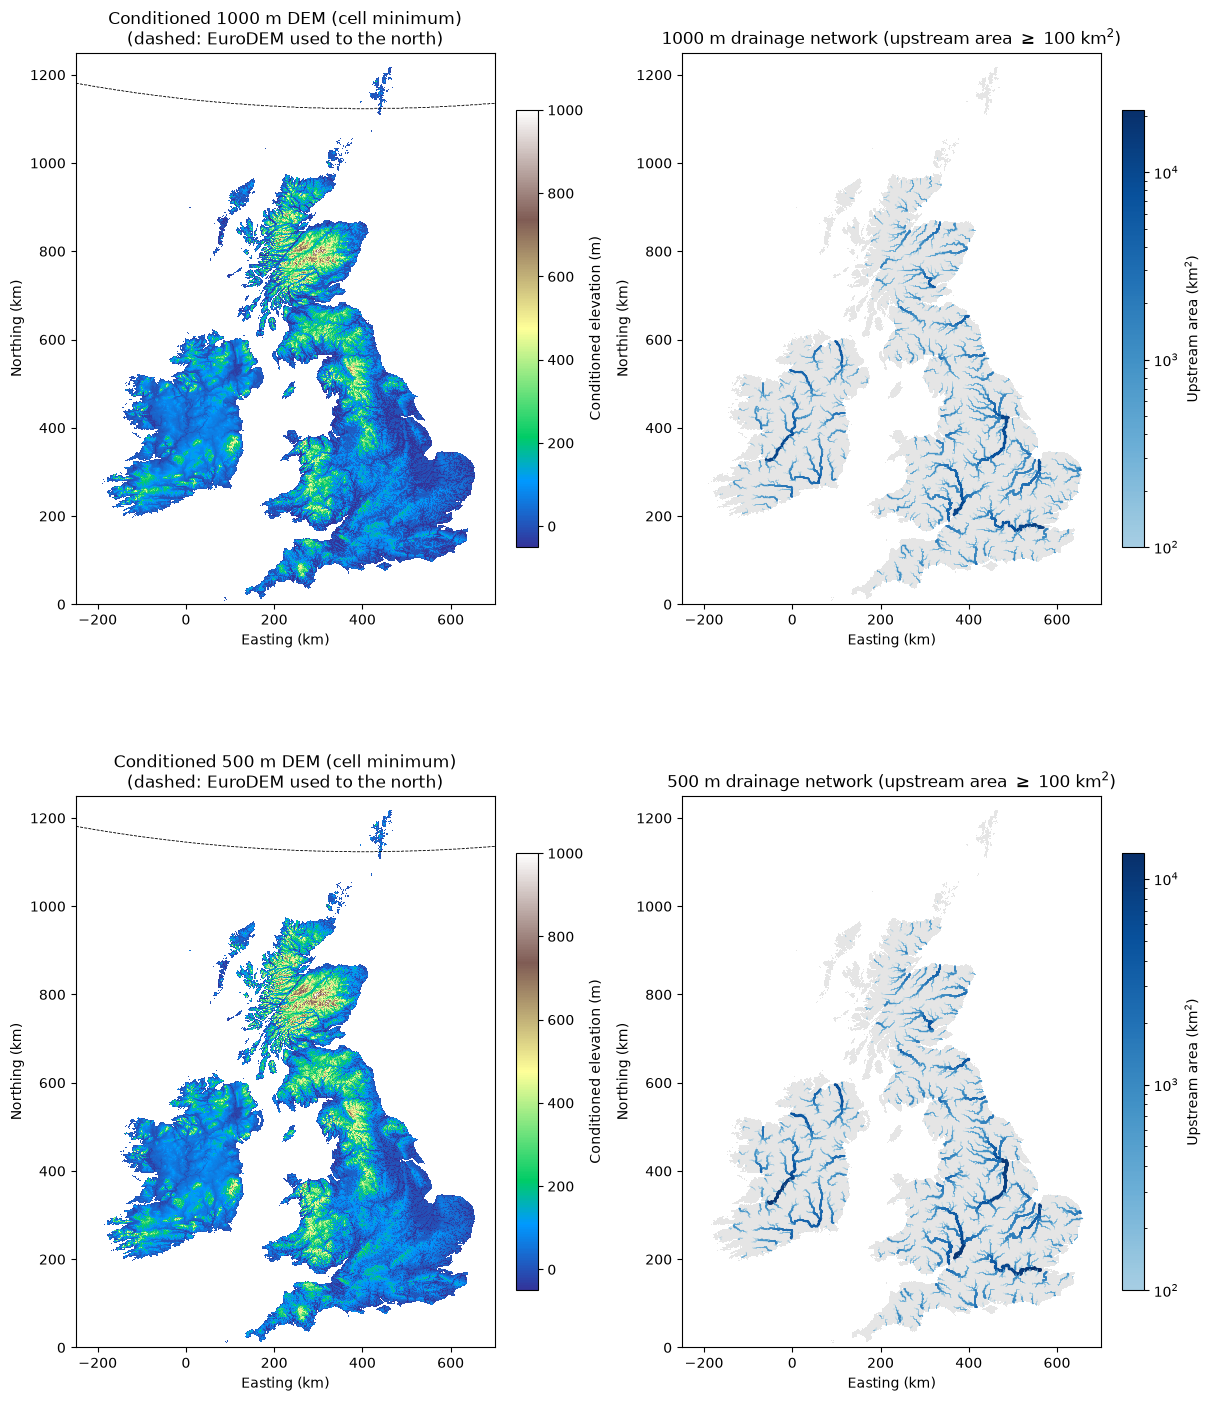

In [17]:
from matplotlib.collections import LineCollection

# Blues without its near-white end, so the smallest rivers still show against the grey land
BLUES = mcolors.LinearSegmentedColormap.from_list('blues', plt.cm.Blues(np.linspace(0.35, 1, 256)))


def flow_lines(g, min_km2, **kw):
    # Segments from each cell with at least min_km2 upstream to its downstream cell (km), coloured by area
    cell_km2 = g.res**2 / 1e6
    r, c = np.nonzero(g.land & (g.acc * cell_km2 >= min_km2))
    k = np.searchsorted(CODES, g.fdir[r, c])
    x, y = X0 + (c + 0.5) * g.res, Y1 - (r + 0.5) * g.res
    segs = np.stack([np.c_[x, y], np.c_[x + DJ[k] * g.res, y - DI[k] * g.res]], axis=1) / 1e3
    area = g.acc[r, c] * cell_km2
    norm = mcolors.LogNorm(vmin=min_km2, vmax=area.max())
    widths = 0.3 + 1.7 * norm(area)
    return LineCollection(segs, array=area, norm=norm, linewidths=widths, capstyle='round', **kw)


fig, axes = plt.subplots(len(grids), 2, figsize=(12, 7.4 * len(grids)), layout='constrained', squeeze=False)
extent = (X0 / 1e3, X1 / 1e3, Y0 / 1e3, Y1 / 1e3)
for (ax_dem, ax_net), g in zip(axes, grids.values()):
    im = ax_dem.imshow(np.where(g.land, g.dem_cond, np.nan), extent=extent, cmap='terrain', vmin=-50, vmax=1000,
                       interpolation='nearest')
    ax_dem.contour(np.where(g.use_eu, 1, 0), levels=[0.5], extent=extent, origin='upper', colors='k', linewidths=0.6,
                   linestyles='--')
    fig.colorbar(im, ax=ax_dem, shrink=0.6, label='Conditioned elevation (m)')
    ax_dem.set_title(f'Conditioned {g.res} m DEM (cell minimum)\n(dashed: EuroDEM used to the north)')

    ax_net.imshow(np.where(g.land, 0.0, np.nan), extent=extent, cmap=mcolors.ListedColormap(['0.9']), interpolation='nearest')
    lines = ax_net.add_collection(flow_lines(g, 100, cmap=BLUES))
    fig.colorbar(lines, ax=ax_net, shrink=0.6, label='Upstream area (km$^2$)')
    ax_net.set_title(f'{g.res} m drainage network (upstream area $\\geq$ 100 km$^2$)')
    for ax in (ax_dem, ax_net):
        ax.set_xlim(extent[:2])
        ax.set_ylim(extent[2:])
        ax.set_xlabel('Easting (km)')
        ax.set_ylabel('Northing (km)')
        ax.set_aspect('equal')

## Metadata

In [18]:
for g in grids.values():
    big = stations['catchment-area'][g.err.index] >= 50
    lines = [
        f'{g.res} m D8 flow direction for the British Isles (GB, island of Ireland, Isle of Man) in British National Grid (EPSG:27700).',
        '',
        'Made by `notebooks/2026-11-02_2_uk-flowdir-1km-500m.ipynb`, with the same method as the 2 km grid (`flowdir_02000_bng.tif`). '
        f'Elevation comes from HydroSHEDS v1 `eu_con_3s` (90 m conditioned DEM): each {g.res} m cell takes the minimum of its 90 m land pixels, '
        'which keeps the burned-in river channels and narrow valleys. Cells not wholly south of 60°N (northern Shetland) use EuroDEM 2023 instead. '
        'A cell is land if it is at least 50% land. '
        f'In GB, OS Open Rivers (2018, canals excluded) rivers with at least {MIN_UP_KM[g.res]} km of channel upstream are enforced: their cells take '
        f'D8 directions along the mapped river and are lowered by {BURN} m. Ireland is DEM-only. '
        'Before rasterising, links that are digitised the wrong way are reversed: these are links on the shortest path from a dead end '
        'in the network to a node that drains to the sea or a canal, mostly where rivers pass under canals. Enforcement is released on river cells '
        f'that conditioning would lift more than {LIFT_TOL} m above the DEM next to a cell more than {LIFT_TOL} m lower. '
        'The DEM is conditioned with Priority-Flood+ε (Barnes et al., 2014), adapted so enforced directions are downhill. D8 directions '
        'are taken from the conditioned DEM, plus the enforced directions on river cells. Every land cell has a strictly downhill path to the sea: '
        'there are no pits, flats, depressions or loops. Coastal cells drain directly to an adjacent sea cell.',
        '',
        f'Against {big.sum()} NRFA gauges of at least 50 km2, the median absolute error in upstream area is {100 * g.err[big].abs().median():.1f}% '
        f'({100 * g.err_dem_only[big].abs().median():.1f}% without river enforcement), and {100 * (g.err[big].abs() > 0.3).mean():.1f}% of gauges '
        f'are more than 30% off. For the {(~big).sum()} gauges of 10-50 km2 the median is {100 * g.err[~big].abs().median():.1f}%.',
        '',
        f'Grid: {g.ncol} x {g.nrow} cells of {g.res} m, extent x {X0} to {X1}, y {Y0} to {Y1} (BNG metres), aligned with the 2 km grid. '
        f'Sea and nodata = {NODATA}.',
        '',
        'Flow direction encoding (as in the HMF 5 km grid): 1 = E, 2 = SE, 4 = S, 8 = SW, 16 = W, 32 = NW, 64 = N, 128 = NE.',
        '',
        'Files:',
        f'- `flowdir_{g.tag}_bng.tif`: flow direction (int16).',
        f'- `flowacc_{g.tag}_bng.tif`: number of {g.res} m cells draining through each cell, including itself (int32).',
        f'- `dem_{g.tag}_bng_conditioned.tif`: conditioned DEM (float64, m). This is a cell-minimum DEM with river cells lowered by {BURN} m, so it is '
        'only for routing, not for e.g. mean elevation or hillslope gradients. Must stay float64 to preserve the ε gradients that the directions are based on.',
    ]
    (path_out / f'flowdir_{g.tag}_bng.tif.md').write_text('\n'.join(lines) + '\n')
    print('\n'.join(lines), end='\n\n')

1000 m D8 flow direction for the British Isles (GB, island of Ireland, Isle of Man) in British National Grid (EPSG:27700).

Made by `notebooks/2026-11-02_2_uk-flowdir-1km-500m.ipynb`, with the same method as the 2 km grid (`flowdir_02000_bng.tif`). Elevation comes from HydroSHEDS v1 `eu_con_3s` (90 m conditioned DEM): each 1000 m cell takes the minimum of its 90 m land pixels, which keeps the burned-in river channels and narrow valleys. Cells not wholly south of 60°N (northern Shetland) use EuroDEM 2023 instead. A cell is land if it is at least 50% land. In GB, OS Open Rivers (2018, canals excluded) rivers with at least 1 km of channel upstream are enforced: their cells take D8 directions along the mapped river and are lowered by 50 m. Ireland is DEM-only. Before rasterising, links that are digitised the wrong way are reversed: these are links on the shortest path from a dead end in the network to a node that drains to the sea or a canal, mostly where rivers pass under canals. Enforcem